# Point-in-time earnings data: how restated fundamentals leak the future into a backtest

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/boshroid/yieldterminal-sec-data/blob/main/notebooks/point-in-time-earnings-backtest.ipynb)

A fundamentals table usually keeps one value per company per quarter: the number the company reports **today** for
that quarter. A backtest that reads it on a past date can use a number that was only filed months or years later.
Nothing errors; the backtest just quietly knows a little about the future.

In this notebook I measure that on real data, for 30 large U.S. companies:

1. **First reported vs latest.** From the free XBRL JSON at `data.sec.gov`, I take every single-quarter revenue and
   net income value each company filed in a 10-Q or 10-K since 2015, and compare the value as **first reported**
   with the value in the **latest** filing that reports the same quarter again.
2. **A ranking illustration.** Each calendar quarter I rank the companies on year-over-year revenue growth, once
   from latest values (what a merged table gives you) and once from first-reported values keyed to the date they
   were filed (what you could have known), and count where the two rankings differ. There are no returns, no
   strategy and no performance numbers here; the point is only whether the inputs differ.
3. **The shortcut.** The `yieldterminal` Python client returns one company's first-reported history with the
   filing link on every figure, and the free results CSV shows a figure I withheld (blank, never zero).

It runs top to bottom with or without network access: the data pulled from `data.sec.gov` is frozen in
`notebooks/data/`, next to this notebook. The method and code follow my dev.to post,
[Backtesting with earnings as first reported](https://dev.to/yieldterminalpro/backtesting-with-earnings-as-first-reported-why-restated-fundamentals-leak-the-future-9nm).

## Setup

`data.sec.gov` asks every client to send a descriptive User-Agent with a contact address and to stay under 10
requests a second. If you run this yourself, put your own name and email in `SEC_USER_AGENT`. Responses are cached
in `.cache/sec/`, so a second run makes no requests at all.

By default the notebook reads the frozen facts in `data/pit_quarterly_facts.csv` when that file exists (it does in
the repository), so the numbers below reproduce exactly. Set the environment variable `PIT_REFRESH=1` to pull
everything again from `data.sec.gov` and overwrite the frozen files. In Colab, where the frozen file is not on disk,
it pulls live and falls back to the copy on GitHub if `data.sec.gov` cannot be reached.

In [1]:
import json
import os
import pathlib
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 120)

SEC_USER_AGENT = os.environ.get("SEC_USER_AGENT", "YieldTerminal Pro research yieldterminalpro@gmail.com")
MIN_SECONDS_BETWEEN_CALLS = 0.15          # about 6 requests a second, under the 10 a second limit
REFRESH = os.environ.get("PIT_REFRESH") == "1"

# 30 large U.S. companies across sectors. Edit freely; nothing below depends on this exact list.
UNIVERSE = ["AAPL", "MSFT", "AMZN", "GOOGL", "META", "NVDA", "TSLA", "JPM", "JNJ", "WMT",
            "PG", "XOM", "CVX", "KO", "PEP", "HD", "UNH", "V", "MA", "DIS",
            "INTC", "CSCO", "ORCL", "IBM", "PFE", "MRK", "T", "VZ", "GE", "BA"]

# Companies tag revenue under different us-gaap concepts, and switch between them over the years.
REVENUE_CONCEPTS = ["Revenues",
                    "RevenueFromContractWithCustomerExcludingAssessedTax",
                    "RevenueFromContractWithCustomerIncludingAssessedTax",
                    "SalesRevenueNet"]
NET_INCOME_CONCEPT = "NetIncomeLoss"
FIRST_PERIOD_END = "2015-01-01"

DATA_DIR = pathlib.Path("data")
CACHE_DIR = pathlib.Path(".cache") / "sec"
DATA_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FACTS_CSV = DATA_DIR / "pit_quarterly_facts.csv"
FROZEN_URL = "https://raw.githubusercontent.com/boshroid/yieldterminal-sec-data/main/notebooks/data/pit_quarterly_facts.csv"


def filing_url(cik, accession):
    """The filing's index page on sec.gov."""
    return f"https://www.sec.gov/Archives/edgar/data/{int(cik)}/{accession.replace('-', '')}/{accession}-index.htm"

## Pull the facts from `data.sec.gov`

The `companyconcept` endpoint returns every value a company ever filed for one XBRL concept. Each value carries
the period (`start`, `end`), the form, the accession number and the `filed` date of the filing it came from. When a
later filing reports the same quarter again (a 10-Q shows the year-ago quarter as a comparative, for example), the
JSON holds another entry with a later `filed` date. Nothing is overwritten, which is what makes "first reported"
recoverable.

I keep 10-Q and 10-K facts (and their amendments) whose period is a single quarter (80 to 100 days; a 10-Q also
tags year-to-date totals) and ends in 2015 or later.

In [2]:
session = requests.Session()
session.headers.update({"User-Agent": SEC_USER_AGENT, "Accept-Encoding": "gzip, deflate"})
_last_call = [0.0]


def get_json(url, cache_name):
    """GET a JSON document with caching, a minimum gap between calls and a back-off on 429/403/503.

    Returns None for a 404 (the company never used that concept)."""
    path = CACHE_DIR / cache_name
    if path.exists():
        text = path.read_text(encoding="utf-8")
        return json.loads(text) if text else None
    status = None
    for attempt in range(5):
        wait = MIN_SECONDS_BETWEEN_CALLS - (time.monotonic() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        response = session.get(url, timeout=30)
        _last_call[0] = time.monotonic()
        status = response.status_code
        if status == 404:
            path.write_text("", encoding="utf-8")
            return None
        if status in (403, 429, 503):
            time.sleep(2 ** attempt)
            continue
        response.raise_for_status()
        path.write_text(response.text, encoding="utf-8")
        return response.json()
    raise RuntimeError(f"Gave up on {url} after repeated status {status}")


def fetch_facts():
    tickers = get_json("https://www.sec.gov/files/company_tickers.json", "company_tickers.json")
    cik_by_ticker = {row["ticker"]: int(row["cik_str"]) for row in tickers.values()}
    rows, calls = [], 0
    for ticker in UNIVERSE:
        cik = cik_by_ticker[ticker]
        for concept in REVENUE_CONCEPTS + [NET_INCOME_CONCEPT]:
            url = f"https://data.sec.gov/api/xbrl/companyconcept/CIK{cik:010d}/us-gaap/{concept}.json"
            data = get_json(url, f"CIK{cik:010d}_{concept}.json")
            calls += 1
            if data is None:
                continue
            for fact in data["units"].get("USD", []):
                rows.append({"ticker": ticker, "cik": cik, "concept": concept, **fact})
    raw = pd.DataFrame(rows)
    print(f"{calls} concept documents for {len(UNIVERSE)} companies, {len(raw):,} USD facts in total")
    raw = raw[raw["form"].isin(["10-Q", "10-K", "10-Q/A", "10-K/A"]) & raw["start"].notna()].copy()
    days = (pd.to_datetime(raw["end"]) - pd.to_datetime(raw["start"])).dt.days
    raw = raw[days.between(80, 100) & (raw["end"] >= FIRST_PERIOD_END)]
    raw["retrieved"] = datetime.now(timezone.utc).date().isoformat()
    cols = ["ticker", "cik", "concept", "start", "end", "val", "accn", "fy", "fp", "form", "filed", "frame", "retrieved"]
    return raw[cols].sort_values(["ticker", "concept", "end", "filed", "accn"]).reset_index(drop=True)


if FACTS_CSV.exists() and not REFRESH:
    facts = pd.read_csv(FACTS_CSV)
    source = f"frozen file {FACTS_CSV.as_posix()}"
else:
    try:
        facts = fetch_facts()
        facts.to_csv(FACTS_CSV, index=False, lineterminator="\n")
        source = f"data.sec.gov (live), frozen to {FACTS_CSV.as_posix()}"
    except Exception as exc:
        if REFRESH:
            raise
        print(f"Live pull failed ({exc}); reading the frozen copy on GitHub instead")
        facts = pd.read_csv(FROZEN_URL)
        source = FROZEN_URL

for col in ("start", "end", "filed"):
    facts[col] = pd.to_datetime(facts[col])
RETRIEVED = pd.Timestamp(facts["retrieved"].iloc[0])

print("Source:", source)
print(f"Retrieved {RETRIEVED.date()}: {len(facts):,} single-quarter facts, {facts['ticker'].nunique()} companies, "
      f"periods ending {facts['end'].min().date()} to {facts['end'].max().date()}, "
      f"filed {facts['filed'].min().date()} to {facts['filed'].max().date()}")
facts.head()

150 concept documents for 30 companies, 15,936 USD facts in total
Source: data.sec.gov (live), frozen to data/pit_quarterly_facts.csv
Retrieved 2026-11-27: 5,262 single-quarter facts, 30 companies, periods ending 2015-01-24 to 2026-11-01, filed 2015-02-18 to 2026-11-20


,ticker,cik,concept,start,end,val,accn,fy,fp,form,filed,frame,retrieved
0,AAPL,320193,NetIncomeLoss,2014-12-28,2015-03-28,13569000000,0001193125-15-153166,2015.0,Q2,10-Q,2015-04-28,NaN,2026-11-27
1,AAPL,320193,NetIncomeLoss,2014-12-28,2015-03-28,13569000000,0001193125-15-356351,2015.0,FY,10-K,2015-10-28,NaN,2026-11-27
2,AAPL,320193,NetIncomeLoss,2014-12-28,2015-03-28,13569000000,0001193125-16-559625,2016.0,Q2,10-Q,2016-04-27,NaN,2026-11-27
3,AAPL,320193,NetIncomeLoss,2014-12-28,2015-03-28,13569000000,0001628280-16-020309,2016.0,FY,10-K,2016-10-26,CY2015Q1,2026-11-27
4,AAPL,320193,NetIncomeLoss,2015-03-29,2015-06-27,10677000000,0001193125-15-259935,2015.0,Q3,10-Q,2015-07-22,NaN,2026-11-27


## 1. First reported vs latest

For each company, metric (revenue or net income) and quarter, I sort the filings that report the quarter by
`filed` date. The earliest one gives the **first-reported** value and its date; the latest one gives roughly what a
fundamentals database shows today.

One rule for revenue: a company can tag the same quarter under more than one revenue concept (Mastercard, for
example, tags both a gross and a net revenue line). Comparing values across concepts would count a concept switch as
a change, so for each quarter I pick one concept, the one in the earliest filing (ties go to the order of
`REVENUE_CONCEPTS`), and compare first and latest within that concept only.

In [3]:
facts["metric"] = np.where(facts["concept"].isin(REVENUE_CONCEPTS), "revenue", "net_income")
facts["concept_order"] = facts["concept"].map({c: i for i, c in enumerate(REVENUE_CONCEPTS + [NET_INCOME_CONCEPT])})
PERIOD = ["ticker", "metric", "start", "end"]
ORDER = PERIOD + ["filed", "concept_order", "accn"]

f = facts.sort_values(ORDER, kind="stable")
chosen = f.groupby(PERIOD, sort=False).head(1)[PERIOD + ["concept"]]
f = f.merge(chosen, on=PERIOD + ["concept"]).sort_values(ORDER, kind="stable")

groups = f.groupby(PERIOD, sort=False)
first, latest = groups.head(1), groups.tail(1)
KEEP = ["val", "filed", "form", "accn"]
fvl = first[["ticker", "cik", "metric", "concept", "start", "end"] + KEEP].merge(
    latest[PERIOD + KEEP], on=PERIOD, suffixes=("_first", "_latest"))
fvl = fvl.merge(groups["accn"].nunique().rename("filings").reset_index(), on=PERIOD)
fvl["changed"] = fvl["val_first"] != fvl["val_latest"]
fvl["change_pct"] = (fvl["val_latest"] / fvl["val_first"] - 1) * 100

summary = fvl.groupby("metric").agg(
    company_quarters=("changed", "size"),
    reported_again_later=("filings", lambda s: int((s > 1).sum())),
    changed=("changed", "sum"),
    changed_more_than_1pct=("change_pct", lambda s: int((s.abs() > 1).sum())),
    changed_more_than_5pct=("change_pct", lambda s: int((s.abs() > 5).sum())),
)
summary.loc["total"] = summary.sum()
summary["changed_share"] = (summary["changed"] / summary["company_quarters"]).map("{:.1%}".format)

n_changed = int(fvl["changed"].sum())
changed_companies = sorted(fvl.loc[fvl["changed"], "ticker"].unique())
print(f"{n_changed:,} of {len(fvl):,} company-quarter values ({n_changed / len(fvl):.1%}) changed after first report, "
      f"at {len(changed_companies)} of {fvl['ticker'].nunique()} companies.")
print("Median size of a change:", f"{fvl.loc[fvl['changed'], 'change_pct'].abs().median():.1f}%")
summary

132 of 2,153 company-quarter values (6.1%) changed after first report, at 15 of 30 companies.
Median size of a change: 5.6%


,company_quarters,reported_again_later,changed,changed_more_than_1pct,changed_more_than_5pct,changed_share
metric,,,,,,
net_income,1085,965,56,38,26,5.2%
revenue,1068,882,76,57,44,7.1%
total,2153,1847,132,95,70,6.1%


Which companies the changes come from. Half the universe never changed a single quarterly revenue or net income
value after first reporting it; the changes cluster in a few companies.

In [4]:
by_company = (fvl[fvl["changed"]].groupby(["ticker", "metric"]).size().unstack(fill_value=0)
              .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False))
print("No change in any quarter:", ", ".join(sorted(set(fvl["ticker"]) - set(changed_companies))))
by_company

No change in any quarter: AAPL, AMZN, CSCO, CVX, GOOGL, HD, INTC, JPM, MA, PEP, UNH, V, VZ, WMT, XOM


metric,net_income,revenue,total
ticker,,,
GE,15,26,41
PFE,6,9,15
TSLA,9,6,15
T,5,7,12
MSFT,6,3,9
BA,4,4,8
JNJ,1,5,6
NVDA,4,1,5
DIS,0,5,5


### Real examples

Every row is the same company, the same XBRL concept and the same quarter, filed twice with different values. I do
not classify why a value changed (a restatement, a business moved to discontinued operations, an accounting change
applied to prior periods, a reclassification, or a company reusing a tag for a different line); the two filing
links in the table let you check each one.

Three that show the problem clearly:

In [5]:
def money(v):
    return f"${v / 1e9:,.2f}B" if abs(v) >= 1e9 else f"${v / 1e6:,.0f}M"


def example_table(rows):
    return pd.DataFrame({
        "ticker": rows["ticker"],
        "metric": rows["metric"],
        "quarter ended": rows["end"].dt.date,
        "first reported": rows["val_first"].map(money),
        "first filed": rows["filed_first"].dt.date.astype(str) + " " + rows["form_first"],
        "latest": rows["val_latest"].map(money),
        "latest filed": rows["filed_latest"].dt.date.astype(str) + " " + rows["form_latest"],
        "change": rows["change_pct"].map("{:+.1f}%".format),
    }).reset_index(drop=True)


SHOWCASE = [("GE", "revenue", "2023-09-30"), ("T", "revenue", "2021-09-30"), ("MSFT", "net_income", "2016-12-31")]
showcase = pd.concat([fvl[(fvl["ticker"] == t) & (fvl["metric"] == m) & (fvl["end"] == e)] for t, m, e in SHOWCASE])
display(example_table(showcase))
for _, r in showcase.iterrows():
    print(f"{r['ticker']} {r['metric']} for the quarter ended {r['end'].date()} ({r['concept']}):")
    print(f"  first  {money(r['val_first']):>9}  {r['form_first']} filed {r['filed_first'].date()}  {filing_url(r['cik'], r['accn_first'])}")
    print(f"  latest {money(r['val_latest']):>9}  {r['form_latest']} filed {r['filed_latest'].date()}  {filing_url(r['cik'], r['accn_latest'])}")

,ticker,metric,quarter ended,first reported,first filed,latest,latest filed,change
0,GE,revenue,2023-09-30,$17.35B,2023-10-24 10-Q,$9.30B,2025-02-03 10-K,-46.4%
1,T,revenue,2021-09-30,$39.92B,2021-11-04 10-Q,$31.33B,2023-02-13 10-K,-21.5%
2,MSFT,net_income,2016-12-31,$5.20B,2017-01-26 10-Q,$6.27B,2018-08-03 10-K,+20.5%


GE revenue for the quarter ended 2023-09-30 (Revenues):
  first    $17.35B  10-Q filed 2023-10-24  https://www.sec.gov/Archives/edgar/data/40545/000004054523000238/0000040545-23-000238-index.htm
  latest    $9.30B  10-K filed 2025-02-03  https://www.sec.gov/Archives/edgar/data/40545/000004054525000015/0000040545-25-000015-index.htm
T revenue for the quarter ended 2021-09-30 (Revenues):
  first    $39.92B  10-Q filed 2021-11-04  https://www.sec.gov/Archives/edgar/data/732717/000073271721000080/0000732717-21-000080-index.htm
  latest   $31.33B  10-K filed 2023-02-13  https://www.sec.gov/Archives/edgar/data/732717/000073271723000011/0000732717-23-000011-index.htm
MSFT net_income for the quarter ended 2016-12-31 (NetIncomeLoss):
  first     $5.20B  10-Q filed 2017-01-26  https://www.sec.gov/Archives/edgar/data/789019/000156459017000654/0001564590-17-000654-index.htm
  latest    $6.27B  10-K filed 2018-08-03  https://www.sec.gov/Archives/edgar/data/789019/000156459018019062/0001564590-18-01

- **GE, revenue, quarter ended Sep 30, 2023.** First reported at about $17.3 billion in the 10-Q filed in October
  2023; the 10-K filed in February 2025 reports the same quarter at about $9.3 billion. A backtest reading the
  merged table on any date in 2023 or 2024 would see a number that did not exist until 2025.
- **AT&T, revenue, quarter ended Sep 30, 2021.** About $39.9 billion as first filed, about $31.3 billion in the
  10-K filed in February 2023.
- **Microsoft, net income, quarter ended Dec 31, 2016.** About $5.2 billion as first filed in January 2017, about
  $6.3 billion in the 10-K filed in August 2018. Changes go up as well as down.

The 20 largest changes in the data, by size:

In [6]:
largest = fvl[fvl["changed"]].assign(size=lambda d: d["change_pct"].abs()).sort_values("size", ascending=False)
example_table(largest.head(20))

,ticker,metric,quarter ended,first reported,first filed,latest,latest filed,change
0,GE,net_income,2022-09-30,$-165M,2022-10-25 10-Q,$161M,2024-02-02 10-K,-197.6%
1,GE,net_income,2017-03-31,$653M,2017-05-05 10-Q,$-83M,2019-02-26 10-K,-112.7%
2,GE,revenue,2015-06-30,$32.75B,2015-07-30 10-Q,$2.69B,2017-02-24 10-K,-91.8%
3,GE,revenue,2015-09-30,$31.68B,2015-11-02 10-Q,$2.66B,2017-02-24 10-K,-91.6%
4,GE,revenue,2015-03-31,$29.36B,2015-05-04 10-Q,$2.87B,2017-02-24 10-K,-90.2%
5,T,net_income,2017-09-30,$3.03B,2017-11-03 10-Q,$4.72B,2020-02-20 10-K,+55.8%
6,GE,revenue,2023-12-31,$19.42B,2024-02-02 10-K,$9.46B,2025-02-03 10-K,-51.3%
7,GE,revenue,2023-06-30,$16.70B,2023-07-25 10-Q,$8.76B,2025-02-03 10-K,-47.6%
8,GE,revenue,2023-09-30,$17.35B,2023-10-24 10-Q,$9.30B,2025-02-03 10-K,-46.4%
9,GE,revenue,2023-03-31,$14.49B,2023-04-25 10-Q,$7.84B,2025-02-03 10-K,-45.9%


## 2. Illustration: ranking on revenue growth, latest vs as first reported

A simple, transparent cross-sectional rule: each calendar quarter, rank the 30 companies on year-over-year revenue
growth for their fiscal quarter that ended in that calendar quarter. I rank on a **decision date** 75 days after the
calendar quarter ends, by which time large companies have normally filed their 10-Q or 10-K.

- **(a) Latest values.** Growth = latest value of the quarter / latest value of the year-ago quarter - 1, the way a
  backtest on a merged table computes it. It ignores filing dates.
- **(b) Point in time.** Growth = the quarter's **first-reported** value / the year-ago value as printed in that same
  filing (falling back to the latest year-ago value filed on or before that date). The company is only ranked if
  that filing was filed on or before the decision date.

Using the comparative from the same filing in (b), rather than the year-ago quarter's own first-reported value,
matters: when a company moves a business to discontinued operations, the new filing restates the year-ago quarter
on the same basis, and that is what an investor could read on the day.

I count how often the inputs and the rankings differ. I do not attach returns: this shows that the two backtests
would be fed different numbers, not that either would make or lose money.

In [7]:
rev = fvl[fvl["metric"] == "revenue"].copy()
rev_facts = f[f["metric"] == "revenue"]
all_rev_facts = facts[facts["metric"] == "revenue"]

# Year-ago quarter: same company, period ending one year earlier (within 10 days, for 52/53-week fiscal years).
pairs = rev.merge(rev, on="ticker", suffixes=("", "_ya"))
target = pairs["end"] - pd.DateOffset(years=1)
pairs = pairs[(pairs["end_ya"] - target).abs().dt.days <= 10]


def year_ago_known_at_filing(row):
    """Year-ago revenue as printed in the filing that first reported the current quarter."""
    same_filing = all_rev_facts[(all_rev_facts["ticker"] == row["ticker"]) & (all_rev_facts["accn"] == row["accn_first"])
                                & (all_rev_facts["concept"] == row["concept"]) & (all_rev_facts["end"] == row["end_ya"])
                                & (all_rev_facts["start"] == row["start_ya"])]
    if len(same_filing):
        return same_filing["val"].iloc[0]
    known = rev_facts[(rev_facts["ticker"] == row["ticker"]) & (rev_facts["end"] == row["end_ya"])
                      & (rev_facts["start"] == row["start_ya"]) & (rev_facts["filed"] <= row["filed_first"])]
    return known["val"].iloc[-1] if len(known) else np.nan


pairs["ya_pit"] = pairs.apply(year_ago_known_at_filing, axis=1)
growth = pd.DataFrame({
    "ticker": pairs["ticker"],
    "period_end": pairs["end"],
    "calendar_quarter": pairs["end"].dt.to_period("Q").astype(str),
    "filed_first": pairs["filed_first"],
    "filed_latest": pairs["filed_latest"],
    "growth_latest": pairs["val_latest"] / pairs["val_latest_ya"] - 1,
    "growth_pit": pairs["val_first"] / pairs["ya_pit"] - 1,
}).dropna(subset=["growth_latest"])
growth = growth.sort_values(["calendar_quarter", "ticker", "period_end"]).drop_duplicates(
    ["calendar_quarter", "ticker"], keep="last")
print(f"{len(growth):,} company-quarters with a year-ago quarter; "
      f"growth differs between (a) and (b) for {int((growth['growth_latest'] - growth['growth_pit']).abs().gt(1e-9).sum())}")

952 company-quarters with a year-ago quarter; growth differs between (a) and (b) for 81


In [8]:
ranked, quarters = [], []
for cq, d in growth.groupby("calendar_quarter"):
    decision = pd.Period(cq, "Q").end_time.normalize() + pd.Timedelta(days=75)
    if decision > RETRIEVED:
        continue                                   # the decision date has not happened yet
    d = d.copy()
    d["decision_date"] = decision
    d["known_by_decision"] = d["filed_first"] <= decision
    d["rank_latest"] = d["growth_latest"].rank(ascending=False, method="min")
    d["rank_pit"] = d["growth_pit"].where(d["known_by_decision"]).rank(ascending=False, method="min")
    d["latest_filed_after_decision"] = d["filed_latest"] > decision
    ranked.append(d)
    top_a = set(d.nsmallest(5, "rank_latest")["ticker"])
    top_b = set(d.dropna(subset=["rank_pit"]).nsmallest(5, "rank_pit")["ticker"])
    both = d.dropna(subset=["rank_pit"])
    quarters.append({
        "calendar_quarter": cq,
        "decision_date": decision.date(),
        "ranked_latest": len(d),
        "ranked_pit": int(d["rank_pit"].notna().sum()),
        "growth_input_differs": int(((d["growth_latest"] - d["growth_pit"]).abs() > 1e-9).sum()),
        "rank_differs": int((d["rank_latest"] != d["rank_pit"]).sum()),
        "top5_swapped": len(top_a - top_b),
        "rank_correlation": round(both["rank_latest"].corr(both["rank_pit"]), 3),
    })
ranked = pd.concat(ranked, ignore_index=True)
by_quarter = pd.DataFrame(quarters)

n_q = len(by_quarter)
print(f"{n_q} quarters ranked, {by_quarter['calendar_quarter'].iloc[0]} to {by_quarter['calendar_quarter'].iloc[-1]}")
print(f"Quarters where some growth input differs:     {int((by_quarter['growth_input_differs'] > 0).sum())} of {n_q}")
print(f"Quarters where the ranking differs:            {int((by_quarter['rank_differs'] > 0).sum())} of {n_q}")
print(f"Quarters where the top 5 differ:               {int((by_quarter['top5_swapped'] > 0).sum())} of {n_q}")
print(f"Company-quarters ranked:                       {int(by_quarter['ranked_latest'].sum())}")
print(f"  whose own growth input differs:              {int(by_quarter['growth_input_differs'].sum())}")
print(f"  ranked at a different place (including companies moved by another company's change): "
      f"{int(by_quarter['rank_differs'].sum())}")
print(f"Company-quarters not yet filed on the decision date (ranked in (a) only): "
      f"{int((by_quarter['ranked_latest'] - by_quarter['ranked_pit']).sum())}")
by_quarter

42 quarters ranked, 2016Q1 to 2026Q2
Quarters where some growth input differs:     32 of 42
Quarters where the ranking differs:            28 of 42
Quarters where the top 5 differ:               8 of 42
Company-quarters ranked:                       924
  whose own growth input differs:              81
  ranked at a different place (including companies moved by another company's change): 305
Company-quarters not yet filed on the decision date (ranked in (a) only): 6


,calendar_quarter,decision_date,ranked_latest,ranked_pit,growth_input_differs,rank_differs,top5_swapped,rank_correlation
0,2016Q1,2016-06-14,22,22,1,11,1,0.938
1,2016Q2,2016-09-13,22,21,1,11,1,0.973
2,2016Q3,2016-12-14,21,20,1,21,1,0.933
3,2016Q4,2017-03-16,17,17,1,4,0,0.985
4,2017Q1,2017-06-14,21,21,4,9,0,0.977
5,2017Q2,2017-09-13,22,22,3,0,0,1.000
6,2017Q3,2017-12-14,22,21,3,15,0,0.904
7,2017Q4,2018-03-16,15,15,1,3,0,0.989
8,2018Q1,2018-06-14,23,23,3,8,0,0.972
9,2018Q2,2018-09-13,24,23,4,14,0,0.994


What the table shows, in the frozen snapshot retrieved on 2026-11-27:

- In most quarters from 2016 to 2023, at least one company's growth number differs between the two versions, and
  a single difference moves every company between the old and the new place by one rank. The top five differ less
  often.
- From 2024 on there are almost no differences. That is not because the problem went away: those quarters have
  simply had less time to be reported again in later filings.
- Calendar fourth quarters rank fewer companies, because most companies tag only the full year in the 10-K, not
  the fourth quarter on its own.
- One difference can be large. In 2023Q4 (next table), GE's revenue growth from latest values is about -44%: the
  latest value of the quarter comes from a 10-K filed in February 2025, while the latest value of the year-ago
  quarter comes from the 10-K filed in February 2024, so the two numbers are on different bases. The 10-K that
  first reported the quarter, filed in February 2024, printed both quarters: growth of about +15%. The
  merged table produces a growth rate that no filing ever showed.

The quarter where the two rankings disagree most, side by side. `latest filed` is the filing the merged-table value
comes from; where it is after the decision date, (a) is using a number nobody could read on that day.

In [9]:
worst = by_quarter.sort_values(["rank_correlation", "rank_differs"], ascending=[True, False]).iloc[0]["calendar_quarter"]
w = ranked[ranked["calendar_quarter"] == worst].sort_values("rank_latest")
print(f"Calendar quarter {worst}, decision date {w['decision_date'].iloc[0].date()}")
pd.DataFrame({
    "ticker": w["ticker"],
    "period end": w["period_end"].dt.date,
    "growth (a) latest": w["growth_latest"].map("{:+.1%}".format),
    "rank (a)": w["rank_latest"].astype(int),
    "growth (b) point in time": w["growth_pit"].map("{:+.1%}".format),
    "rank (b)": w["rank_pit"].astype("Int64"),
    "latest filed": w["filed_latest"].dt.date,
    "after decision?": np.where(w["latest_filed_after_decision"], "yes", ""),
}).reset_index(drop=True)

Calendar quarter 2023Q4, decision date 2024-03-15


,ticker,period end,growth (a) latest,rank (a),growth (b) point in time,rank (b),latest filed,after decision?
0,NVDA,2023-10-29,+205.5%,1,+205.5%,1,2024-11-20,yes
1,MSFT,2023-12-31,+17.6%,2,+17.6%,2,2025-01-29,yes
2,V,2023-12-31,+8.8%,3,+8.8%,4,2025-01-31,yes
3,CSCO,2023-10-28,+7.6%,4,+7.6%,5,2024-11-19,yes
4,JNJ,2023-12-31,+7.3%,5,+7.3%,6,2024-02-16,
5,ORCL,2023-11-30,+5.4%,6,+5.4%,7,2024-12-10,yes
6,WMT,2023-10-31,+5.2%,7,+5.2%,8,2024-12-06,yes
7,PG,2023-12-31,+3.2%,8,+3.2%,9,2025-01-22,yes
8,T,2023-12-31,+2.2%,9,+2.2%,10,2024-02-23,
9,AAPL,2023-12-30,+2.1%,10,+2.1%,11,2025-01-31,yes


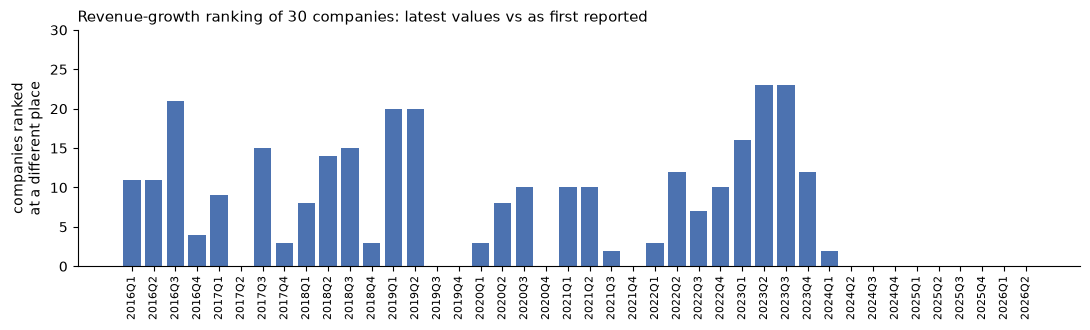

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(by_quarter["calendar_quarter"], by_quarter["rank_differs"], color="#4C72B0")
ax.set_ylabel("companies ranked\nat a different place")
ax.set_title("Revenue-growth ranking of 30 companies: latest values vs as first reported", loc="left", fontsize=11)
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, 30)
plt.tight_layout()
plt.show()

### Save the results

The frozen inputs are already in `data/pit_quarterly_facts.csv`. These two files hold the results above, so they can
be checked or reused without running anything.

In [11]:
out = fvl.drop(columns=["start"]).rename(columns={"end": "quarter_end"}).copy()
out["url_first"] = [filing_url(c, a) for c, a in zip(out["cik"], out["accn_first"])]
out["url_latest"] = [filing_url(c, a) for c, a in zip(out["cik"], out["accn_latest"])]
for col in ("quarter_end", "filed_first", "filed_latest"):
    out[col] = out[col].dt.date
out["change_pct"] = out["change_pct"].round(4)
out.sort_values(["ticker", "metric", "quarter_end"]).to_csv(
    DATA_DIR / "pit_first_vs_latest.csv", index=False, lineterminator="\n")

rk = ranked[["calendar_quarter", "decision_date", "ticker", "period_end", "filed_first", "filed_latest",
             "growth_latest", "rank_latest", "growth_pit", "rank_pit", "known_by_decision"]].copy()
for col in ("decision_date", "period_end", "filed_first", "filed_latest"):
    rk[col] = rk[col].dt.date
rk[["growth_latest", "growth_pit"]] = rk[["growth_latest", "growth_pit"]].round(6)
rk["rank_pit"] = rk["rank_pit"].astype("Int64")
rk["rank_latest"] = rk["rank_latest"].astype(int)
rk.to_csv(DATA_DIR / "pit_revenue_growth_rankings.csv", index=False, lineterminator="\n")

for p in sorted(DATA_DIR.glob("pit_*.csv")):
    print(f"{p.as_posix()}  {p.stat().st_size / 1024:,.0f} KB")

data/pit_first_vs_latest.csv  741 KB
data/pit_quarterly_facts.csv  649 KB
data/pit_revenue_growth_rankings.csv  75 KB


## 3. The shortcut: first-reported history from the `yieldterminal` client

I built [YieldTerminal Pro](https://yieldterminalpro.com/developers) around this problem. I read each company's
results release (Form 8-K or 6-K) and publish revenue, net income and diluted EPS from it, keyed to the filing date,
with the filing link on every figure. A figure is published only when the release's table agrees with a second
source; otherwise it is withheld, and a withheld figure is blank, never zero. The company response also carries up
to 20 quarters of XBRL history as first reported, with the accession number on each value, a derived fourth quarter
marked `d`, and a later restatement kept separately as `r` instead of written over the original.

`yieldterminal.sample()` needs no key and covers NVDA, WMT, TJX, HD and TGT.

In [12]:
%pip install -q --disable-pip-version-check yieldterminal

Note: you may need to restart the kernel to use updated packages.


In [13]:
import yieldterminal

SAMPLE_JSON = DATA_DIR / "yieldterminal_sample_NVDA.json"
try:
    co = yieldterminal.sample("NVDA")
    sample_source = "live sample endpoint"
    if REFRESH or not SAMPLE_JSON.exists():
        SAMPLE_JSON.write_text(json.dumps(co, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")
except Exception as exc:
    print(f"Sample endpoint not reachable ({exc}); using the frozen copy")
    co = json.loads(SAMPLE_JSON.read_text(encoding="utf-8"))
    sample_source = f"frozen copy {SAMPLE_JSON.as_posix()}"

print(f"{co['ticker']} ({co['company']}), {sample_source}, latest filing {co['latest_filed']}")
print("Results releases, as read from each 8-K (withheld = not published, never zero):")
pd.DataFrame([{
    "filed": r["filed"],
    "form": r["form"],
    "revenue": r.get("revenue_text"),
    "net income": r.get("net_income_text") or "withheld",
    "diluted EPS": r.get("eps_text"),
    "filing": r["source_url"],
} for r in co["results"]])

NVDA (NVIDIA CORP), live sample endpoint, latest filing 2026-11-17
Results releases, as read from each 8-K (withheld = not published, never zero):


,filed,form,revenue,net income,diluted EPS,filing
0,2026-11-17,8-K,$115.80 billion (+103% vs $57.00 billion a year earlier),withheld,$2.70 (vs $1.30 a year earlier),https://www.sec.gov/Archives/edgar/data/1045810/000104581026000088/q3fy27pr.htm
1,2026-08-26,8-K,$96.22 billion (+106% vs $46.74 billion a year earlier),$59.69 billion (+125.9% vs $26.42 billion a year earlier),$2.46 (vs $1.08 a year earlier),https://www.sec.gov/Archives/edgar/data/1045810/000104581026000073/q2fy27pr.htm
2,2026-05-20,8-K,$81.62 billion (+85% vs $44.06 billion a year earlier),$58.32 billion (+210.6% vs $18.78 billion a year earlier),$2.39 (vs $0.76 a year earlier),https://www.sec.gov/Archives/edgar/data/1045810/000104581026000051/q1fy27pr.htm
3,2026-02-25,8-K,$68.13 billion (+73% vs $39.33 billion a year earlier),withheld,$1.76 (vs $0.89 a year earlier),https://www.sec.gov/Archives/edgar/data/1045810/000104581026000019/q4fy26pr.htm
4,2025-11-19,8-K,$57.01 billion (+62% vs $35.08 billion a year earlier),$31.91 billion (+65.3% vs $19.31 billion a year earlier),$1.30 (vs $0.78 a year earlier),https://www.sec.gov/Archives/edgar/data/1045810/000104581025000228/q3fy26pr.htm


Net income for NVDA's latest release is withheld in this response: the figure could not be confirmed against a
second source, so it is left blank instead of guessed. The first-reported history, with a link to the filing each
value came from:

In [14]:
def history_frame(company):
    rows = []
    for q in company["quarterly_history"]:
        rev, ni, eps = q.get("revenue") or {}, q.get("net_income") or {}, q.get("eps") or {}
        accession = rev.get("a") or ni.get("a")
        rows.append({
            "period_end": q["period_end"],
            "fiscal": f"{q['fiscal_year']} {q['fiscal_period']}",
            "revenue": rev.get("v"),
            "net_income": ni.get("v"),
            "eps_diluted": eps.get("v"),
            "derived_q4": bool(rev.get("d")),
            "restated_later": any("r" in x for x in (rev, ni, eps)),
            "filing": filing_url(company["cik"], accession) if accession else None,
        })
    return pd.DataFrame(rows)


hist = history_frame(co)
print(co.get("history_note", ""))
hist.tail(8)

XBRL concepts used. Revenue: Revenues; Net income: NetIncomeLoss; Diluted EPS: EarningsPerShareDiluted. Diluted EPS first reported before a share split is not shown (8 quarters).


,period_end,fiscal,revenue,net_income,eps_diluted,derived_q4,restated_later,filing
12,2024-10-27,2025 Q3,35082000000,19309000000,0.78,False,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581024000316/0001045810-24-000316-index.htm
13,2025-01-26,2025 Q4,39331000000,22091000000,NaN,True,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581025000023/0001045810-25-000023-index.htm
14,2025-04-27,2026 Q1,44062000000,18775000000,0.76,False,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581025000116/0001045810-25-000116-index.htm
15,2025-07-27,2026 Q2,46743000000,26422000000,1.08,False,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581025000209/0001045810-25-000209-index.htm
16,2025-10-26,2026 Q3,57006000000,31910000000,1.30,False,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581025000230/0001045810-25-000230-index.htm
17,2026-01-25,2026 Q4,68127000000,42960000000,NaN,True,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581026000021/0001045810-26-000021-index.htm
18,2026-04-26,2027 Q1,81615000000,58321000000,2.39,False,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581026000052/0001045810-26-000052-index.htm
19,2026-07-26,2027 Q2,96221000000,59688000000,2.46,False,False,https://www.sec.gov/Archives/edgar/data/1045810/000104581026000075/0001045810-26-000075-index.htm


A quick consistency check: the client's first-reported NVDA revenue against the first-reported values I computed
from `data.sec.gov` above, for the quarters both have (the client also has derived fourth quarters, which part 1
leaves out).

In [15]:
mine = fvl[(fvl["ticker"] == "NVDA") & (fvl["metric"] == "revenue")][["end", "val_first", "val_latest"]]
mine = mine.assign(period_end=mine["end"].dt.strftime("%Y-%m-%d"))
check = hist[["period_end", "revenue", "derived_q4"]].merge(mine, on="period_end")
check = check[~check["derived_q4"]]
print(f"{int((check['revenue'] == check['val_first']).sum())} of {len(check)} common quarters equal the "
      f"first-reported value from data.sec.gov")
check[["period_end", "revenue", "val_first", "val_latest"]].tail(6)

15 of 15 common quarters equal the first-reported value from data.sec.gov


,period_end,revenue,val_first,val_latest
9,2024-10-27,35082000000,35082000000,35082000000
10,2025-04-27,44062000000,44062000000,44062000000
11,2025-07-27,46743000000,46743000000,46743000000
12,2025-10-26,57006000000,57006000000,57006000000
13,2026-04-26,81615000000,81615000000,81615000000
14,2026-07-26,96221000000,96221000000,96221000000


### A withheld figure: HP Inc.

The free results CSV (`https://yieldterminalpro.com/data/earnings-results.csv`, one row per published results
filing, no key) shows how a withheld figure looks in bulk data. In HP Inc.'s 8-K filed on Nov 24, 2026, revenue and
diluted EPS were published and net income was withheld, so its cells are empty rather than zero.

In [16]:
CSV_URL = "https://yieldterminalpro.com/data/earnings-results.csv"
HPQ_CSV = DATA_DIR / "yieldterminal_results_HPQ.csv"
try:
    results_csv = pd.read_csv(CSV_URL, storage_options={"User-Agent": SEC_USER_AGENT})
    hpq = results_csv[results_csv["ticker"] == "HPQ"].sort_values("filed", ascending=False)
    if REFRESH or not HPQ_CSV.exists():
        hpq.to_csv(HPQ_CSV, index=False, lineterminator="\n")
    print(f"Free results CSV: {len(results_csv):,} published filings; HPQ rows below")
except Exception as exc:
    print(f"Results CSV not reachable ({exc}); using the frozen HPQ rows")
    hpq = pd.read_csv(HPQ_CSV)

show = hpq[["filed", "form", "quarter", "revenue", "net_income", "eps_diluted", "source_url"]].head(3).copy()
for col in ("revenue", "net_income"):
    show[col] = show[col].map(lambda v: "blank (withheld)" if pd.isna(v) else money(v))
show

Free results CSV: 17,126 published filings; HPQ rows below


,filed,form,quarter,revenue,net_income,eps_diluted,source_url
17,2026-11-24,8-K,ended Oct 2026,$16.00B,blank (withheld),0.84,https://www.sec.gov/Archives/edgar/data/47217/000004721726000054/hp103126exhibit991q426.htm
3711,2026-08-26,8-K,ended Jul 2026,$15.68B,$661M,0.71,https://www.sec.gov/Archives/edgar/data/47217/000004721726000048/hp73126exhibit991q326.htm
7406,2026-05-27,8-K,ended Apr 2026,$14.41B,$450M,0.49,https://www.sec.gov/Archives/edgar/data/47217/000004721726000027/hp43026exhibit991q226.htm


In [17]:
latest_hpq = hpq.iloc[0]
print("Filed:", latest_hpq["filed"], latest_hpq["form"], latest_hpq["accession"])
print("Net income:", "withheld (blank)" if pd.isna(latest_hpq["net_income"]) else latest_hpq["net_income"])
print("Filing:", latest_hpq["source_url"])

# With a free key (https://yieldterminalpro.com/developers) the same company is one call away.
# The key is read from the environment and never printed.
if os.environ.get("YIELDTERMINAL_API_KEY"):
    client = yieldterminal.Client()
    try:
        hpq_api = client.company("HPQ")
        r0 = hpq_api["results"][0]
        print("API:", r0["filed"], "net income:", r0.get("net_income_text") or "withheld", r0["source_url"])
    except yieldterminal.YieldTerminalError as exc:
        print("API call not available on this key:", exc)
else:
    print("YIELDTERMINAL_API_KEY not set; skipping the keyed company() call.")

Filed: 2026-11-24 8-K 0000047217-26-000054
Net income: withheld (blank)
Filing: https://www.sec.gov/Archives/edgar/data/47217/000004721726000054/hp103126exhibit991q426.htm
YIELDTERMINAL_API_KEY not set; skipping the keyed company() call.


## What this shows, and what it does not

- On 30 large U.S. companies, most single-quarter revenue and net income values in 10-Q and 10-K XBRL data since
  2015 never changed after they were first filed, but a minority did, some by a lot, and they cluster in a few
  companies. A merged "latest value" table silently mixes those later numbers into earlier dates.
- Ranked on year-over-year revenue growth, the latest-value version and the point-in-time version are fed different
  inputs in many quarters and put companies in a different order in some of them. Any backtest built on the
  latest-value table inherits that difference. This notebook does not measure returns and says nothing about whether
  either ranking would have made money.
- Limits: 30 large companies are not a representative sample; only quarters tagged as a single quarter are
  included (most fourth quarters are only tagged as full years); a change in value is not classified by cause; and
  the XBRL `filed` date is the 10-Q or 10-K date, which is later than the company's results release (8-K), so a
  point-in-time series keyed to it is safe but late.

To do the same for your own universe, change `UNIVERSE`, set `PIT_REFRESH=1` and run all cells.

*Data: XBRL company facts from data.sec.gov (U.S. Securities and Exchange Commission), and YieldTerminal Pro
(yieldterminalpro.com), read from companies' filings.*

**Educational content, not investment advice.**